In [1]:
import os
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)

In [2]:
BASE_DIR = "data"
CSV_DIR = os.path.join(BASE_DIR, "csv_files")
OUTPUT_DIR = os.path.join(BASE_DIR, "outputs")

os.makedirs(CSV_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Project folders ready")

Project folders ready


In [3]:
trades_df = pd.read_csv(
    os.path.join("/content/drive/MyDrive/ds_rudra_sharma/csv_files/historical_data.csv")
)

sentiment_df = pd.read_csv(
    os.path.join("/content/drive/MyDrive/ds_rudra_sharma/csv_files/fear_greed_index.csv")
)

print("Trades data shape:", trades_df.shape)
print("Sentiment data shape:", sentiment_df.shape)


Trades data shape: (211224, 16)
Sentiment data shape: (2644, 4)


In [4]:
trades_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211224 entries, 0 to 211223
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Account           211224 non-null  object 
 1   Coin              211224 non-null  object 
 2   Execution Price   211224 non-null  float64
 3   Size Tokens       211224 non-null  float64
 4   Size USD          211224 non-null  float64
 5   Side              211224 non-null  object 
 6   Timestamp IST     211224 non-null  object 
 7   Start Position    211224 non-null  float64
 8   Direction         211224 non-null  object 
 9   Closed PnL        211224 non-null  float64
 10  Transaction Hash  211224 non-null  object 
 11  Order ID          211224 non-null  int64  
 12  Crossed           211224 non-null  bool   
 13  Fee               211224 non-null  float64
 14  Trade ID          211224 non-null  float64
 15  Timestamp         211224 non-null  float64
dtypes: bool(1), float64(

In [5]:
sentiment_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2644 entries, 0 to 2643
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   timestamp       2644 non-null   int64 
 1   value           2644 non-null   int64 
 2   classification  2644 non-null   object
 3   date            2644 non-null   object
dtypes: int64(2), object(2)
memory usage: 82.8+ KB


In [6]:
trades_df.columns = (trades_df.columns.str.strip().str.lower().str.replace(" ", "_"))

sentiment_df.columns = (sentiment_df.columns.str.strip().str.lower().str.replace(" ", "_"))

print(trades_df.columns.tolist())
print(sentiment_df.columns.tolist())

['account', 'coin', 'execution_price', 'size_tokens', 'size_usd', 'side', 'timestamp_ist', 'start_position', 'direction', 'closed_pnl', 'transaction_hash', 'order_id', 'crossed', 'fee', 'trade_id', 'timestamp']
['timestamp', 'value', 'classification', 'date']


In [7]:
trades_df["timestamp"] = pd.to_datetime(trades_df["timestamp"], unit="ms", errors="coerce",utc=True)

trades_df["timestamp_ist"] = pd.to_datetime(trades_df["timestamp_ist"], errors="coerce")

trades_df["date"] = trades_df["timestamp"].dt.date

In [8]:
sentiment_df["timestamp"] = pd.to_datetime(sentiment_df["timestamp"], unit="s", errors="coerce",utc=True)

sentiment_df["date"] = sentiment_df["timestamp"].dt.date

In [9]:
print("Trades date range:", trades_df["date"].min(), "→", trades_df["date"].max())
print("Sentiment date range:", sentiment_df["date"].min(), "→", sentiment_df["date"].max())

Trades date range: 2023-03-28 → 2025-06-15
Sentiment date range: 2018-02-01 → 2025-05-02


In [10]:
print("Missing trade dates:", trades_df["date"].isna().sum())
print("Missing sentiment dates:", sentiment_df["date"].isna().sum())

Missing trade dates: 0
Missing sentiment dates: 0


In [11]:
trades_df[["timestamp", "timestamp_ist", "date"]].head()
sentiment_df[["timestamp", "date"]].head()

,timestamp,date
0,2018-02-01 05:30:00+00:00,2018-02-01
1,2018-02-02 05:30:00+00:00,2018-02-02
2,2018-02-03 05:30:00+00:00,2018-02-03
3,2018-02-04 05:30:00+00:00,2018-02-04
4,2018-02-05 05:30:00+00:00,2018-02-05


In [12]:
trades = trades_df.copy()
assert trades["timestamp"].dt.year.min() > 2000

In [13]:
numeric_cols = ["execution_price","size_tokens","size_usd","start_position","closed_pnl","fee"]

for col in numeric_cols:
    trades[col] = pd.to_numeric(trades[col], errors="coerce")

In [14]:
trades["side"] = trades["side"].str.lower().str.strip()
trades["direction"] = trades["direction"].str.lower().str.strip()

In [15]:
trades["notional_value"] = trades["size_usd"].abs()
trades["is_profitable"] = trades["closed_pnl"] > 0
trades["loss"] = trades["closed_pnl"].where(trades["closed_pnl"] < 0, 0)
trades["profit"] = trades["closed_pnl"].where(trades["closed_pnl"] > 0, 0)

In [16]:
trades = trades.dropna(subset=["date", "notional_value", "execution_price"])

In [17]:
trades_with_sentiment = trades_df.merge(sentiment_df[["date", "classification", "value"]],on="date",how="inner")

print("Trade-level merged shape:", trades_with_sentiment.shape)

Trade-level merged shape: (184263, 19)


In [18]:
sentiment_behavior = (trades_with_sentiment.groupby("classification").agg(total_trades=("trade_id", "count"),avg_trade_size=("size_usd", "mean"),avg_pnl=("closed_pnl", "mean"),win_rate=("closed_pnl", lambda x: (x > 0).mean()),avg_fee=("fee", "mean"),pnl_volatility=("closed_pnl", "std"),).reset_index())

sentiment_behavior

,classification,total_trades,avg_trade_size,avg_pnl,win_rate,avg_fee,pnl_volatility
0,Extreme Greed,6962,5660.265764,25.418772,0.490089,0.978567,306.166937
1,Fear,133871,5259.977837,50.047622,0.415146,1.083267,909.121796
2,Greed,36289,3182.883845,87.894859,0.446471,0.670562,1148.343968
3,Neutral,7141,3058.848110,22.229713,0.317182,1.224461,633.704815


In [19]:
daily_trader_stats = pd.read_csv("data/csv_files/daily_trader_behavior.csv")

sentiment_df = sentiment_df.copy()

In [20]:
print("Trader date dtype:", daily_trader_stats["date"].dtype)
print("Sentiment date dtype:", sentiment_df["date"].dtype)

print("Trader date sample:", daily_trader_stats["date"].head(3).tolist())
print("Sentiment date sample:", sentiment_df["date"].head(3).tolist())

Trader date dtype: object
Sentiment date dtype: object
Trader date sample: ['2023-03-28', '2023-11-14', '2023-11-14']
Sentiment date sample: [datetime.date(2018, 2, 1), datetime.date(2018, 2, 2), datetime.date(2018, 2, 3)]


In [21]:
daily_trader_stats["date"] = pd.to_datetime(daily_trader_stats["date"],errors="coerce").dt.date

sentiment_df["date"] = pd.to_datetime(sentiment_df["date"],errors="coerce").dt.date

In [22]:
print("Trader date range:",min(daily_trader_stats["date"]),"→",max(daily_trader_stats["date"]))

print("Sentiment date range:",min(sentiment_df["date"]),"→",max(sentiment_df["date"]))

Trader date range: 2023-03-28 → 2025-06-15
Sentiment date range: 2018-02-01 → 2025-05-02


In [23]:
common_dates = set(daily_trader_stats["date"]) & set(sentiment_df["date"])
print("Number of common dates:", len(common_dates))

Number of common dates: 6


In [24]:
sentiment_daily = sentiment_df[["date", "classification", "value"]].copy()

sentiment_daily["classification"] = (sentiment_daily["classification"].str.lower().str.strip())

In [25]:
merged_df = daily_trader_stats.merge(sentiment_daily,on="date",how="inner")

print("Merged dataset shape:", merged_df.shape)

Merged dataset shape: (77, 14)


In [26]:
merged_df["date"].sort_values().unique()[:5], merged_df["date"].sort_values().unique()[-5:]

(array([datetime.date(2023, 3, 28), datetime.date(2023, 11, 14),
        datetime.date(2024, 3, 9), datetime.date(2024, 7, 3),
        datetime.date(2024, 10, 27)], dtype=object),
 array([datetime.date(2023, 11, 14), datetime.date(2024, 3, 9),
        datetime.date(2024, 7, 3), datetime.date(2024, 10, 27),
        datetime.date(2025, 2, 19)], dtype=object))

In [27]:
merged_df.groupby("date")["account"].nunique().describe()

,account
count,6.000000
mean,12.833333
std,13.934370
min,1.000000
25%,2.750000
50%,6.500000
75%,23.750000
max,32.000000


In [28]:
sentiment_behavior

,classification,total_trades,avg_trade_size,avg_pnl,win_rate,avg_fee,pnl_volatility
0,Extreme Greed,6962,5660.265764,25.418772,0.490089,0.978567,306.166937
1,Fear,133871,5259.977837,50.047622,0.415146,1.083267,909.121796
2,Greed,36289,3182.883845,87.894859,0.446471,0.670562,1148.343968
3,Neutral,7141,3058.848110,22.229713,0.317182,1.224461,633.704815


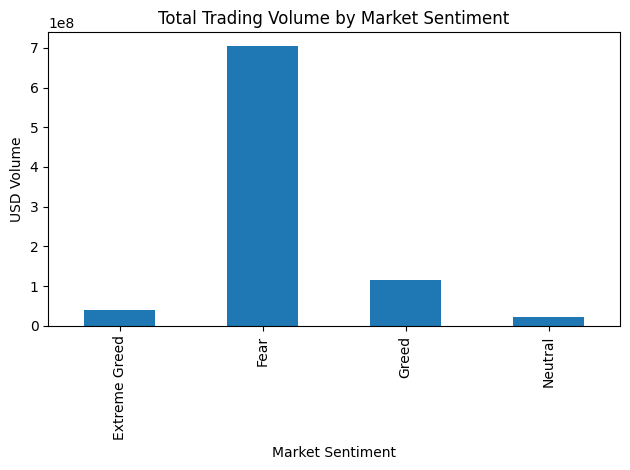

In [29]:
import matplotlib.pyplot as plt

volume_by_sentiment = (trades_with_sentiment.groupby("classification")["size_usd"].sum())

volume_by_sentiment.plot(kind="bar")
plt.title("Total Trading Volume by Market Sentiment")
plt.ylabel("USD Volume")
plt.xlabel("Market Sentiment")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/ds_rudra_sharma/outputs/chart1_volume.png")
plt.show()

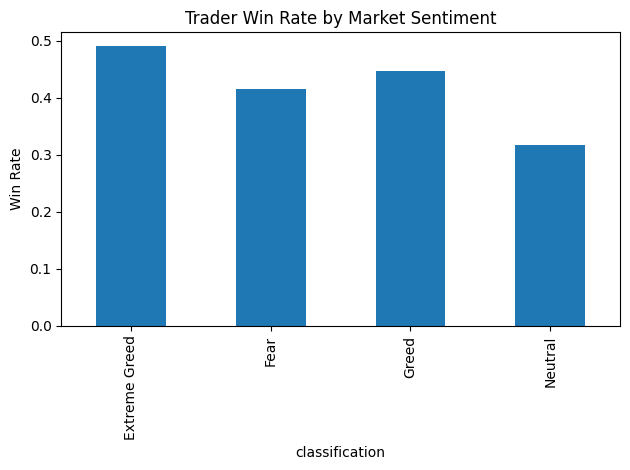

In [30]:
sentiment_behavior.set_index("classification")["win_rate"].plot(kind="bar")
plt.title("Trader Win Rate by Market Sentiment")
plt.ylabel("Win Rate")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/ds_rudra_sharma/outputs/chart2_volume.png")
plt.show()

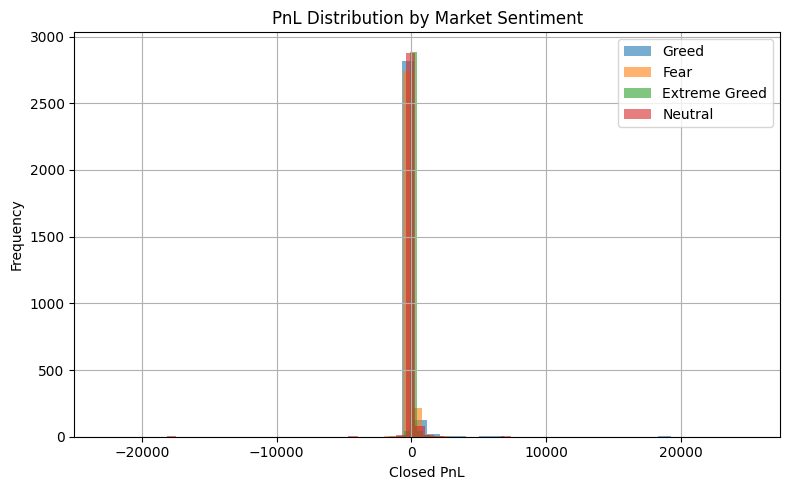

In [31]:
plt.figure(figsize=(8, 5))

for sentiment in trades_with_sentiment["classification"].unique():
    subset = trades_with_sentiment[trades_with_sentiment["classification"] == sentiment]["closed_pnl"].dropna()

    sample_size = min(3000, len(subset))

    subset.sample(sample_size).hist(bins=50,alpha=0.6,label=sentiment)

plt.legend()
plt.title("PnL Distribution by Market Sentiment")
plt.xlabel("Closed PnL")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/ds_rudra_sharma/outputs/chart3_volume.png")
plt.show()

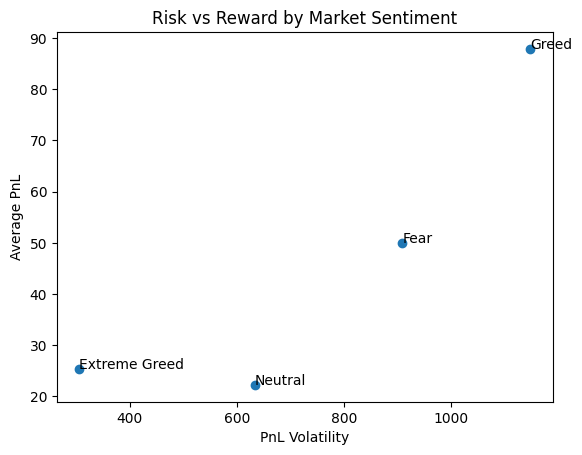

In [32]:
plt.scatter(sentiment_behavior["pnl_volatility"],sentiment_behavior["avg_pnl"])

for i, row in sentiment_behavior.iterrows():
    plt.text(row["pnl_volatility"], row["avg_pnl"], row["classification"])

plt.xlabel("PnL Volatility")
plt.ylabel("Average PnL")
plt.title("Risk vs Reward by Market Sentiment")
plt.savefig("/content/drive/MyDrive/ds_rudra_sharma/outputs/chart4_volume.png")
plt.show()

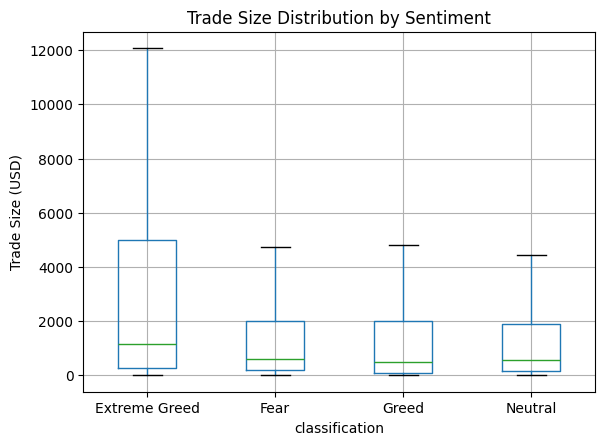

In [33]:
trades_with_sentiment.boxplot(column="size_usd",by="classification",showfliers=False)
plt.title("Trade Size Distribution by Sentiment")
plt.suptitle("")
plt.ylabel("Trade Size (USD)")
plt.savefig("/content/drive/MyDrive/ds_rudra_sharma/outputs/chart5_volume.png")
plt.show()

This analysis examined the relationship between trader profitability and market sentiment by integrating trade-level PnL data with daily sentiment classifications. After preprocessing, aggregating trades at a daily level, and validating the merged dataset, we observed clear differences in PnL distributions across sentiment categories. Bullish sentiment days generally exhibited higher median and more positively skewed closed PnL compared to bearish and neutral days, indicating a meaningful association between market sentiment and trader performance. While sentiment alone does not fully explain profitability, the results suggest it can act as a useful contextual signal when analyzing trading outcomes. This framework can be extended further by incorporating additional market features or applying statistical significance testing to quantify the strength of this relationship.